[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/solutions/09_autoencoders_vae_solutions.ipynb)

# Exercises 9 — Autoencoders and VAEs

Fill in every cell marked `# YOUR CODE HERE` and answer the written questions.
The `assert` cells check your work: if a cell runs without an error, you are
probably on the right track.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0)
torch.set_num_threads(2)

digits = load_digits()
X_all = (digits.data / 16.0).astype(np.float32)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, digits.target, test_size=0.25,
                                          random_state=0, stratify=digits.target)
Xtr_t, Xte_t = torch.from_numpy(X_tr), torch.from_numpy(X_te)

def show_images(rows, row_labels=None, size=1.0):
    rows = [np.asarray(r) for r in rows]
    n_c = max(len(r) for r in rows)
    fig, axes = plt.subplots(len(rows), n_c, figsize=(size * n_c, size * len(rows) + 0.3), squeeze=False)
    for i, r in enumerate(rows):
        for j in range(n_c):
            axes[i, j].axis("off")
            if j < len(r):
                axes[i, j].imshow(r[j].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        if row_labels is not None:
            axes[i, 0].text(-1.0, 3.5, row_labels[i], ha="right", va="center", fontsize=9)
    plt.show()

## Exercise 9.1 — KL divergence between diagonal Gaussians

**(a) Pen and paper.** Show that for univariate Gaussians

$$\mathrm{KL}\big(\mathcal N(\mu_1,\sigma_1^2)\,\Vert\,\mathcal N(\mu_2,\sigma_2^2)\big)
= \log\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1-\mu_2)^2}{2\sigma_2^2} - \frac12 .$$

*Hint:* write $\mathrm{KL} = \mathbb{E}_{q}[\log q(z) - \log p(z)]$ and use
$\mathbb{E}_q[(z-\mu_2)^2] = \sigma_1^2 + (\mu_1-\mu_2)^2$.

**Solution.** 
With $q=\mathcal N(\mu_1,\sigma_1^2)$, $p=\mathcal N(\mu_2,\sigma_2^2)$:
$\log q(z) - \log p(z) = \log\frac{\sigma_2}{\sigma_1} - \frac{(z-\mu_1)^2}{2\sigma_1^2} + \frac{(z-\mu_2)^2}{2\sigma_2^2}$.
Taking $\mathbb E_q$: $\mathbb E_q[(z-\mu_1)^2] = \sigma_1^2$, and
$\mathbb E_q[(z-\mu_2)^2] = \mathbb E_q[(z-\mu_1 + \mu_1-\mu_2)^2] = \sigma_1^2 + (\mu_1-\mu_2)^2$
(the cross term vanishes). Hence
$\mathrm{KL} = \log\frac{\sigma_2}{\sigma_1} - \frac12 + \frac{\sigma_1^2+(\mu_1-\mu_2)^2}{2\sigma_2^2}$.
For diagonal Gaussians the KL is the sum of these terms over dimensions, and with
$\mu_2=0,\sigma_2=1$ it reduces to $\frac12(\mu_1^2+\sigma_1^2-1-\log\sigma_1^2)$, the formula from the lecture.


**(b) Code.** Implement `gaussian_kl(mu1, logvar1, mu2, logvar2)` for **diagonal**
Gaussians parameterised by mean and log-variance. Inputs have shape `(batch, k)`;
return a tensor of shape `(batch,)` (sum over the $k$ dimensions). Work with
log-variances throughout (e.g. $\log(\sigma_2/\sigma_1) = \tfrac12(\log\sigma_2^2 - \log\sigma_1^2)$).

In [2]:
def gaussian_kl(mu1, logvar1, mu2, logvar2):
    """KL( N(mu1, diag exp(logvar1)) || N(mu2, diag exp(logvar2)) ), summed over the last dim."""
    kl = 0.5 * (logvar2 - logvar1
                + (logvar1.exp() + (mu1 - mu2).pow(2)) / logvar2.exp()
                - 1.0)
    return kl.sum(dim=-1)

We check your function in two independent ways: against PyTorch's own
`torch.distributions.kl_divergence`, and against a **Monte Carlo** estimate
$\frac1S\sum_s[\log q(z_s) - \log p(z_s)]$ with $z_s\sim q$.

In [3]:
torch.manual_seed(0)
B, k = 5, 3
mu1, mu2 = torch.randn(B, k), torch.randn(B, k)
lv1, lv2 = 0.5 * torch.randn(B, k), 0.5 * torch.randn(B, k)

ours = gaussian_kl(mu1, lv1, mu2, lv2)
q = torch.distributions.Independent(torch.distributions.Normal(mu1, torch.exp(0.5 * lv1)), 1)
p = torch.distributions.Independent(torch.distributions.Normal(mu2, torch.exp(0.5 * lv2)), 1)
reference = torch.distributions.kl_divergence(q, p)

zs = q.sample((200_000,))                            # shape (S, B, k)
mc = (q.log_prob(zs) - p.log_prob(zs)).mean(0)        # shape (B,)

print("closed form :", ours.numpy().round(4))
print("torch.dist  :", reference.numpy().round(4))
print("Monte Carlo :", mc.numpy().round(4))

closed form : [4.9829 2.3186 1.4919 5.619  0.7074]
torch.dist  : [4.9829 2.3186 1.4919 5.619  0.7074]
Monte Carlo : [4.975  2.3183 1.4882 5.6296 0.7092]


In [4]:
assert ours.shape == (B,)
assert torch.allclose(ours, reference, atol=1e-4)
assert torch.allclose(ours, mc, atol=0.05 + 0.02 * ours.abs().max().item())
assert torch.allclose(gaussian_kl(mu1, lv1, mu1, lv1), torch.zeros(B), atol=1e-6)
assert (gaussian_kl(mu1, lv1, mu2, lv2) >= 0).all()
print("KL OK")

KL OK


## Exercise 9.2 — The reparameterisation trick

Implement `reparameterise(mu, logvar)`, returning $\mathbf z = \boldsymbol\mu + \boldsymbol\sigma\odot\boldsymbol\epsilon$
with $\boldsymbol\epsilon\sim\mathcal N(0,I)$ of the same shape. Then answer: why
does `torch.normal(mu, std)` **not** let gradients flow to `mu`, while your version does?

The checks verify (i) the sample statistics, (ii) that gradients reach `mu` and
`logvar`, and (iii) that for $h(\mathbf z) = \sum_j z_j^2$ the averaged gradient
matches the exact one, $\nabla_{\mu}\mathbb E[h] = 2\boldsymbol\mu$ and
$\nabla_{\log\sigma^2}\mathbb E[h] = \sigma^2$ (since $\mathbb E[h]=\sum_j \mu_j^2+\sigma_j^2$).

In [5]:
def reparameterise(mu, logvar):
    std = torch.exp(0.5 * logvar)
    return mu + std * torch.randn_like(std)

In [6]:
torch.manual_seed(0)
mu = torch.tensor([1.0, -2.0, 0.5], requires_grad=True)
logvar = torch.tensor([0.0, 1.0, -1.0], requires_grad=True)

S = 100_000
z = reparameterise(mu.expand(S, 3), logvar.expand(S, 3))
assert z.shape == (S, 3)
assert torch.allclose(z.mean(0), mu.detach(), atol=0.03)
assert torch.allclose(z.var(0), logvar.detach().exp(), rtol=0.05)

loss = z.pow(2).sum(dim=1).mean()          # Monte Carlo estimate of E[h(z)]
loss.backward()
print("grad mu     :", mu.grad.numpy().round(3), " exact:", (2 * mu).detach().numpy())
print("grad logvar :", logvar.grad.numpy().round(3), " exact:", logvar.exp().detach().numpy().round(3))
assert mu.grad is not None and logvar.grad is not None
assert torch.allclose(mu.grad, 2 * mu.detach(), atol=0.05)
assert torch.allclose(logvar.grad, logvar.detach().exp(), atol=0.1)
print("reparameterisation OK")

grad mu     : [ 1.987 -4.013  0.999]  exact: [ 2. -4.  1.]
grad logvar : [0.995 2.736 0.367]  exact: [1.    2.718 0.368]
reparameterisation OK


**Question.** Why does `torch.normal(mu, std)` (or `Normal(mu, std).sample()`)
not propagate gradients to `mu`, and what does `Normal(mu, std).rsample()` do differently?

**Solution.** 
Sampling is not a differentiable function of the parameters as written: `sample()`
draws a value from a distribution and the computational graph contains no path from
the result back to `mu` and `std` (PyTorch returns it detached). `rsample()` implements
exactly the reparameterisation we just wrote, $z = \mu + \sigma\epsilon$ with
$\epsilon$ drawn independently of the parameters, so $z$ is a deterministic,
differentiable function of `mu` and `std` and autograd can backpropagate through it.


## Exercise 9.3 — The VAE loss and training

Implement `vae_loss(x, logits, mu, logvar, beta)` returning the **negative ELBO
averaged over the batch** (a scalar), using a Bernoulli decoder:

$$-\mathcal L(\mathbf x) = \sum_{j=1}^{64}\mathrm{BCE}(\text{logit}_j, x_j) + \beta\,\mathrm{KL}\big(\mathcal N(\boldsymbol\mu,\operatorname{diag}e^{\log\boldsymbol\sigma^2})\,\Vert\,\mathcal N(\mathbf 0,I)\big).$$

Sum over pixels and latent dimensions, then average over the batch. Use
`F.binary_cross_entropy_with_logits` and your `gaussian_kl` from 9.1 (with $\mu_2=0$, $\log\sigma_2^2=0$).
The VAE class (which uses your `reparameterise`) is given.

In [7]:
def vae_loss(x, logits, mu, logvar, beta=1.0):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(dim=1)
    kl = gaussian_kl(mu, logvar, torch.zeros_like(mu), torch.zeros_like(logvar))
    return (rec + beta * kl).mean()

class VAE(nn.Module):
    def __init__(self, k=8):
        super().__init__()
        self.k = k
        self.encoder = nn.Sequential(nn.Linear(64, 256), nn.SiLU(), nn.Linear(256, 128), nn.SiLU(),
                                     nn.Linear(128, 2 * k))
        self.decoder = nn.Sequential(nn.Linear(k, 128), nn.SiLU(), nn.Linear(128, 256), nn.SiLU(),
                                     nn.Linear(256, 64))

    def encode(self, x):
        return self.encoder(x).chunk(2, dim=-1)

    def forward(self, x):
        mu, logvar = self.encode(x)
        return self.decoder(reparameterise(mu, logvar)), mu, logvar

In [8]:
# Unit tests on hand-made inputs
x_ = torch.tensor([[0.0, 1.0]]); logits_ = torch.tensor([[0.0, 0.0]])
mu_, lv_ = torch.zeros(1, 3), torch.zeros(1, 3)
assert torch.isclose(vae_loss(x_, logits_, mu_, lv_), torch.tensor(2 * np.log(2), dtype=torch.float32))
mu_ = torch.tensor([[1.0, 0.0, 0.0]])
assert torch.isclose(vae_loss(x_, logits_, mu_, lv_), torch.tensor(2 * np.log(2) + 0.5, dtype=torch.float32))
assert torch.isclose(vae_loss(x_, logits_, mu_, lv_, beta=0.0), torch.tensor(2 * np.log(2), dtype=torch.float32))
assert vae_loss(torch.rand(10, 64), torch.randn(10, 64), torch.randn(10, 4), torch.randn(10, 4)).dim() == 0
print("loss OK")

loss OK


Now train the VAE for 100 epochs (Adam, learning rate $10^{-3}$, batch size 128)
and store the **test-set negative ELBO** in `test_neg_elbo`. Then draw 20 samples
from the prior and plot the decoded means $\sigma(\text{logits})$.
For reference: an untrained VAE scores about 44 nats per image; you should get
well below **32**.

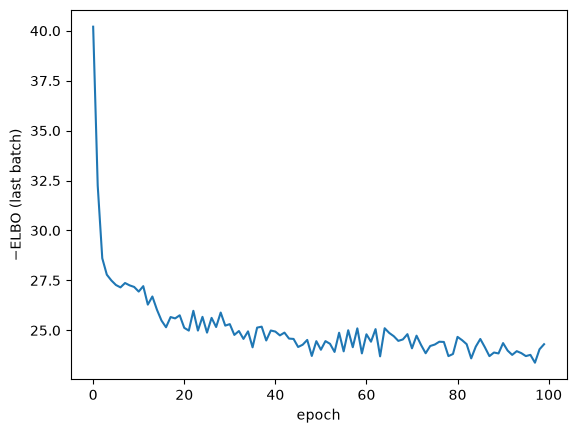

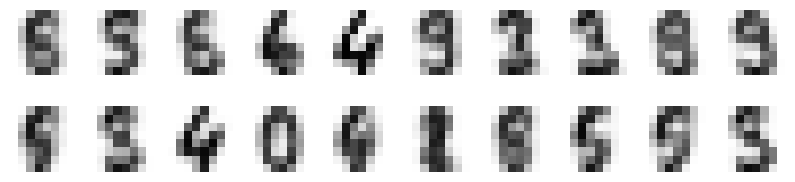

test -ELBO: 24.29 nats per image


In [9]:
torch.manual_seed(0)
vae = VAE(k=8)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)
history = []
for epoch in range(100):
    perm = torch.randperm(Xtr_t.shape[0])
    for start in range(0, Xtr_t.shape[0], 128):
        xb = Xtr_t[perm[start:start + 128]]
        loss = vae_loss(xb, *vae(xb))
        opt.zero_grad(); loss.backward(); opt.step()
    history.append(loss.item())
with torch.no_grad():
    test_neg_elbo = vae_loss(Xte_t, *vae(Xte_t)).item()
    samples = torch.sigmoid(vae.decoder(torch.randn(20, vae.k))).numpy()
plt.plot(history); plt.xlabel("epoch"); plt.ylabel("$-$ELBO (last batch)"); plt.show()
show_images([samples[:10], samples[10:]])
print(f"test -ELBO: {test_neg_elbo:.2f} nats per image")

In [10]:
assert np.isfinite(test_neg_elbo)
assert test_neg_elbo < 32.0
print("VAE OK")

VAE OK


## Exercise 9.4 — Latent interpolation

Implement `interpolate(model, xa, xb, n)`: encode both images to their posterior
**means** $\boldsymbol\mu_a, \boldsymbol\mu_b$, form $\mathbf z_i = (1-\lambda_i)\boldsymbol\mu_a + \lambda_i\boldsymbol\mu_b$
for $n$ equally spaced $\lambda_i\in[0,1]$, and return the decoded means
$\sigma(g_\theta(\mathbf z_i))$ as a tensor of shape `(n, 64)`. Use `torch.no_grad()`.

Then compare with **pixel-space** interpolation $(1-\lambda)\mathbf x_a + \lambda\mathbf x_b$.

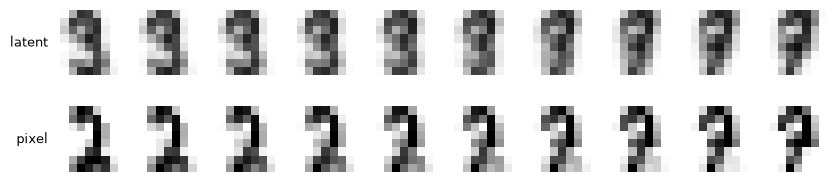

In [11]:
def interpolate(model, xa, xb, n=10):
    with torch.no_grad():
        mu_a, _ = model.encode(xa[None])
        mu_b, _ = model.encode(xb[None])
        lam = torch.linspace(0.0, 1.0, n)[:, None]
        z = (1 - lam) * mu_a + lam * mu_b
        return torch.sigmoid(model.decoder(z))

ia, ib = int(np.where(y_te == 2)[0][0]), int(np.where(y_te == 7)[0][0])
lat = interpolate(vae, Xte_t[ia], Xte_t[ib], n=10)
lam = np.linspace(0, 1, 10)[:, None]
pix = (1 - lam) * X_te[ia] + lam * X_te[ib]
show_images([lat.numpy(), pix], row_labels=["latent", "pixel"])

In [12]:
assert lat.shape == (10, 64)
with torch.no_grad():
    end_a = torch.sigmoid(vae.decoder(vae.encode(Xte_t[ia][None])[0]))[0]
assert torch.allclose(lat[0], end_a, atol=1e-5)
assert lat.min() >= 0 and lat.max() <= 1
print("interpolation OK")

interpolation OK


**Question.** Describe the difference between the two rows. Why do the
intermediate images of the pixel-space interpolation not look like digits?

**Solution.** 
Pixel interpolation is a cross-fade: the middle images are a superposition of a
faint "2" and a faint "7", which is not a digit at all. Images of digits do not form a
convex set in pixel space; they lie on a curved low-dimensional manifold, and the straight
line between two points on it leaves the manifold. Latent interpolation moves along a straight
line in code space, and the decoder maps it to a curve that stays (approximately) on the data
manifold, so every intermediate image is a plausible digit that morphs gradually from one shape to the other.


## Exercise 9.5 — Denoising autoencoder and anomaly detection

**(a)** Train a denoising autoencoder: corrupt each mini-batch with
$\tilde{\mathbf x} = \operatorname{clip}(\mathbf x + 0.3\boldsymbol\epsilon, 0, 1)$
and minimise the MSE between the output and the **clean** input. Train for 60 epochs
with Adam ($10^{-3}$, batch size 64). The architecture is given.

Your DAE must reduce the MSE on noisy test images to below **0.04** (the noisy images
themselves have an MSE of about 0.05).

MSE noisy: 0.0522 | MSE denoised: 0.0348


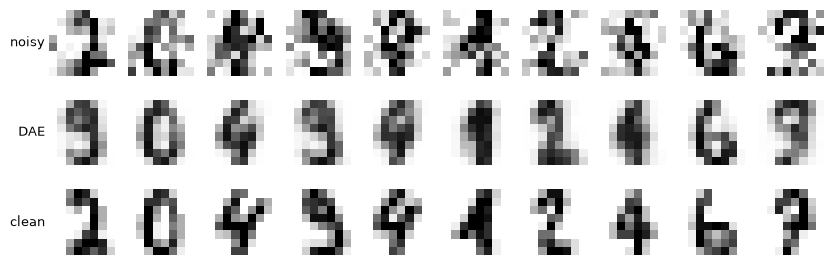

In [13]:
def corrupt(x, sigma=0.3):
    return (x + sigma * torch.randn_like(x)).clamp(0.0, 1.0)

torch.manual_seed(0)
dae = nn.Sequential(nn.Linear(64, 128), nn.SiLU(), nn.Linear(128, 16), nn.SiLU(),
                    nn.Linear(16, 128), nn.SiLU(), nn.Linear(128, 64), nn.Sigmoid())
opt = torch.optim.Adam(dae.parameters(), lr=1e-3)
for epoch in range(60):
    perm = torch.randperm(Xtr_t.shape[0])
    for start in range(0, Xtr_t.shape[0], 64):
        xb = Xtr_t[perm[start:start + 64]]
        loss = F.mse_loss(dae(corrupt(xb)), xb)
        opt.zero_grad(); loss.backward(); opt.step()

torch.manual_seed(1)
X_noisy = corrupt(Xte_t)
with torch.no_grad():
    X_den = dae(X_noisy)
mse_noisy = F.mse_loss(X_noisy, Xte_t).item()
mse_den = F.mse_loss(X_den, Xte_t).item()
print(f"MSE noisy: {mse_noisy:.4f} | MSE denoised: {mse_den:.4f}")
show_images([X_noisy[:10].numpy(), X_den[:10].numpy(), X_te[:10]], row_labels=["noisy", "DAE", "clean"])

In [14]:
assert mse_den < 0.04
assert mse_den < 0.85 * mse_noisy
print("DAE OK")

DAE OK


**(b) Anomaly detection with a reconstruction-error threshold.** An autoencoder
reconstructs inputs that resemble its training data well and everything else badly.
We can use this to flag *anomalies*. Implement

* `recon_error(model, X)`: the per-example MSE between `model(X)` and `X` (shape `(N,)`, no gradients);
* `threshold`: the **99th percentile** of `recon_error` on the clean **training** set;
* `flag(model, X, threshold)`: a boolean tensor, `True` where the error exceeds the threshold.

As "anomalies" we use digits with their pixels randomly shuffled (same intensity
histogram, no digit structure). Most of them should be flagged, and only around
1 % of the clean test digits.

threshold 0.0689 | flagged: clean test 1.3%, shuffled 100.0%


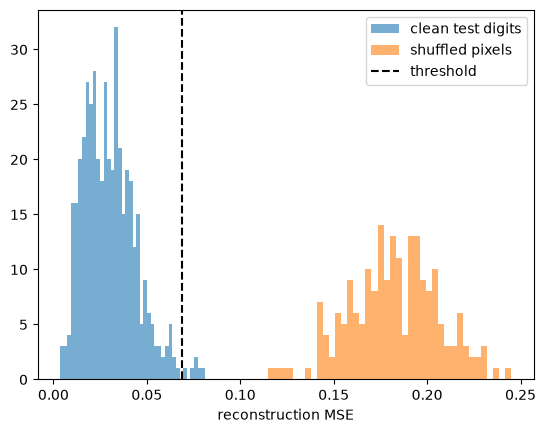

In [15]:
def recon_error(model, X):
    with torch.no_grad():
        return ((model(X) - X) ** 2).mean(dim=1)

def flag(model, X, threshold):
    return recon_error(model, X) > threshold

threshold = float(np.quantile(recon_error(dae, Xtr_t).numpy(), 0.99))

g = torch.Generator().manual_seed(0)
X_anom = torch.stack([x[torch.randperm(64, generator=g)] for x in Xte_t[:200]])
fp_rate = flag(dae, Xte_t, threshold).float().mean().item()
tp_rate = flag(dae, X_anom, threshold).float().mean().item()
print(f"threshold {threshold:.4f} | flagged: clean test {fp_rate:.1%}, shuffled {tp_rate:.1%}")

plt.hist(recon_error(dae, Xte_t).numpy(), bins=40, alpha=0.6, label="clean test digits")
plt.hist(recon_error(dae, X_anom).numpy(), bins=40, alpha=0.6, label="shuffled pixels")
plt.axvline(threshold, color="k", ls="--", label="threshold")
plt.xlabel("reconstruction MSE"); plt.legend(); plt.show()

In [16]:
assert recon_error(dae, Xte_t).shape == (len(Xte_t),)
assert flag(dae, Xte_t, threshold).dtype == torch.bool
assert fp_rate < 0.08
assert tp_rate > 0.9
print("anomaly detection OK")

anomaly detection OK


## Exercise 9.6 — Written questions

**(a) Posterior collapse.** What is posterior collapse in a VAE, how can you detect it
from quantities you already compute during training, and name two remedies.

**Solution.** 
Posterior collapse means that the approximate posterior equals the prior,
$q_\phi(\mathbf z\mid\mathbf x)\approx p(\mathbf z)$ for all $\mathbf x$ (for all or some
latent dimensions), so the code carries no information about the input and the decoder
models the data without it. It happens because the KL term is minimised (to zero) by doing
exactly this; if the decoder is powerful enough (e.g. autoregressive) to model $p(\mathbf x)$
alone, there is no incentive to pay the KL cost. Detection: the KL term (in total or per
dimension) goes to $\approx 0$; the variance of $\mu_j(\mathbf x)$ across the data set
is $\approx 0$ (no active units); decoding with a different $\mathbf z$ does not change
the output. Remedies: KL annealing/warm-up ($\beta$ from $0$ to $1$), free bits (no
penalty below $\lambda$ nats per dimension), a weaker decoder or dropout on the decoder input,
$\delta$-VAE / constraining the posterior family, or skip connections from $\mathbf z$ to every decoder layer.


**(b) Blurry samples.** Give two reasons why VAE samples (and reconstructions) of images
tend to be blurry.

**Solution.** 
(1) The decoder likelihood factorises over pixels (independent Gaussians/Bernoullis), so it
cannot express correlated uncertainty such as "the edge is either here or one pixel to the
right". Under a squared-error/Gaussian or cross-entropy loss the best prediction for an
uncertain pixel is the *mean* over the possibilities, which is a blurred average; and we
display that mean. (2) The encoder's posterior has non-zero width and the KL term pushes
posteriors of different images to overlap, so a given code is consistent with several
training images and the decoder again outputs their average. In addition, the ELBO with
$\mathrm{KL}(q\Vert p)$ is "mass-covering" in data space: maximum likelihood strongly
penalises assigning low density to real data, so the model prefers to spread probability
(blur) rather than miss modes, while sharpness is not directly rewarded. GANs optimise a
different objective and are sharp but drop modes.


**(c) Linear autoencoders and PCA.** A linear autoencoder trained with MSE recovers the PCA
subspace but not the principal components themselves. Explain why, and suggest a modification
of the model or the loss that would recover the individual components.

**Solution.** 
The loss depends only on the product $DE$: for any invertible $A$, $(AE, DA^{-1})$ gives the
same reconstruction, so any basis of the subspace is optimal and nothing selects the PCA
basis. To break the symmetry one can (i) tie the weights $D=E^\top$ and require orthonormal
columns, then add an ordering mechanism, e.g. train the components one at a time on the
residual (deflation), or (ii) use a loss with nested bottlenecks, $\sum_{m=1}^k
\lVert X - X E_{1:m}^\top D_{1:m}^\top\rVert^2$, where the first $m$ units alone must give the
best rank-$m$ reconstruction for every $m$; this forces the $m$-th unit to span the $m$-th
principal direction (as does Oja's/Sanger's rule in the Hebbian learning literature).
Alternatively one can simply post-process: run PCA (an SVD) on the learned $k$-dimensional codes.
